In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cvxpy as cp
from scipy.integrate import odeint

import epyestim
import epyestim.covid19 as covid19

In [25]:
def non_uniform_savgol(x, y, window, polynom):
    """
    Applies a Savitzky-Golay filter to y with non-uniform spacing
    as defined in x

    x : array_like  (MUST BE ORDERED)
    y : array_like  same length as x
    window : int (odd)
    polynom : int   must be smaller than window

    Returns np.array of the smoothed y values
    """
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    if len(x) != len(y):
        raise ValueError('"x" and "y" must be of the same size')
    if len(x) < window:
        raise ValueError('The data size must be larger than the window size')
    if type(window) is not int:
        raise TypeError('"window" must be an integer')
    if window % 2 == 0:
        raise ValueError('The "window" must be an odd integer')
    if type(polynom) is not int:
        raise TypeError('"polynom" must be an integer')
    if polynom >= window:
        raise ValueError('"polynom" must be less than "window"')

    half_window = window // 2
    polynom += 1

    A = np.empty((window, polynom))
    tA = np.empty((polynom, window))
    t = np.empty(window)
    y_smoothed = np.full(len(y), np.nan)

    for i in range(half_window, len(x) - half_window):
        # Center a window of x values on x[i]
        for j in range(window):
            t[j] = x[i + j - half_window] - x[i]

        # Design matrix A and its transpose
        for j in range(window):
            r = 1.0
            for k in range(polynom):
                A[j, k] = r
                tA[k, j] = r
                r *= t[j]

        tAA = np.linalg.inv(np.matmul(tA, A))
        coeffs = np.matmul(tAA, tA)  # pseudoinverse of the design matrix

        # c0 is the smoothed value at y[i]
        y_smoothed[i] = 0
        for j in range(window):
            y_smoothed[i] += coeffs[0, j] * y[i + j - half_window]

        # At the beginning/end, store all polynomial coefficients
        if i == half_window:
            first_coeffs = np.zeros(polynom)
            for j in range(window):
                for k in range(polynom):
                    first_coeffs[k] += coeffs[k, j] * y[j]
        elif i == len(x) - half_window - 1:
            last_coeffs = np.zeros(polynom)
            for j in range(window):
                for k in range(polynom):
                    last_coeffs[k] += coeffs[k, j] * y[len(y) - window + j]

    # Extrapolate at the left border
    for i in range(half_window):
        y_smoothed[i] = 0
        x_i = 1
        for j in range(polynom):
            y_smoothed[i] += first_coeffs[j] * x_i
            x_i *= x[i] - x[half_window]

    # Extrapolate at the right border
    for i in range(len(x) - half_window, len(x)):
        y_smoothed[i] = 0
        x_i = 1
        for j in range(polynom):
            y_smoothed[i] += last_coeffs[j] * x_i
            x_i *= x[i] - x[-half_window - 1]

    return y_smoothed



cdf = pd.read_csv('data/PointLoma_sewage_qPCR.csv')
cdf['Sample_Date'] = pd.to_datetime(cdf['Sample_Date'])
cdf = cdf.set_index('Sample_Date')

COL = 'Mean viral gene copies/L'

# x-values in days (float) since first sample
days = (cdf.index - cdf.index[0]).total_seconds().values / 86400.0

cdf[COL] = non_uniform_savgol(days, cdf[COL].values, 5, 1)

# convert to daily via interpolation
date_ind = pd.date_range(cdf.index.min(), cdf.index.max(), freq='D')
cdf = cdf.reindex(date_ind)
cdf = cdf.interpolate()



def eclipse_model(y, t, b, k, delta, p, mu, c):
    T, I1, I2, Vi, Vni = y
    return [
        -b * Vi * T,
        b * Vi * T - k * I1,
        k * I1 - delta * I2,
        p * mu * I2 - c * Vi,
        p * (1. - mu) * I2 - c * Vni,
    ]


b = 5e-5
c_clear = 10
k = 6
mu = 1.0e-4
p = 1e5
delta = 0.5

t = np.linspace(0, 40, 41)
y0 = [1.33e5, 0, 1. / 30, 0, 0]
sol = odeint(eclipse_model, y0, t, args=(b, k, delta, p, mu, c_clear))

kernel = sol[:, 3:].sum(axis=1)
kernel = kernel / kernel.sum()
kernel = kernel[1:]            # drop first day (concentration = 0)
kernel_flipped = kernel[::-1]


n = len(cdf)
L = len(kernel)

tiledMat = np.zeros((n, n))
for j in range(n):
    tiledMat[j, max(j - L + 1, 0):(j + 1)] = kernel_flipped[max(L - j - 1, 0):L]

infects = np.dot(np.linalg.pinv(tiledMat), cdf[COL].values)
infects = pd.Series(infects, index=cdf.index)


cases = pd.read_csv('data/cases.csv', index_col=0)
cases = cases[cases['catchment'] == 'PointLoma']
cases = cases[(cases.index >= '2021-04-01') & (cases.index <= '2022-07-01')]
cases.index = pd.to_datetime(cases.index)
cases = cases.groupby(pd.Grouper(freq='D'))[['new_cases']].sum()
cases['cases'] = cases['new_cases'].rolling(window=7, center=True, min_periods=0).mean()

# restrict everything to the overlapping date range
minInd = max(cdf.index.min(), cases.index.min())
maxInd = min(cdf.index.max(), cases.index.max())

cdf = cdf.loc[minInd:maxInd]
cases = cases.loc[minInd:maxInd]
infects = infects.loc[minInd:maxInd]

# put on a common daily index
common = infects.index.intersection(cases.index)
infects = infects.loc[common]
cases = cases.loc[common]


x = cp.Variable()
cost = cp.norm(infects.values * x - cases['cases'].values, 2)
prob = cp.Problem(cp.Minimize(cost))
prob.solve(solver=cp.CLARABEL)

# clip negatives from the unregularized pseudoinverse before converting to int
infects = (infects * float(x.value)).clip(lower=0).round().astype(int)

/var/folders/s2/nry612l527j2xxdsq0_70h6m0000gn/T/ipykernel_32269/451316150.py:91: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  cdf['Sample_Date'] = pd.to_datetime(cdf['Sample_Date'])


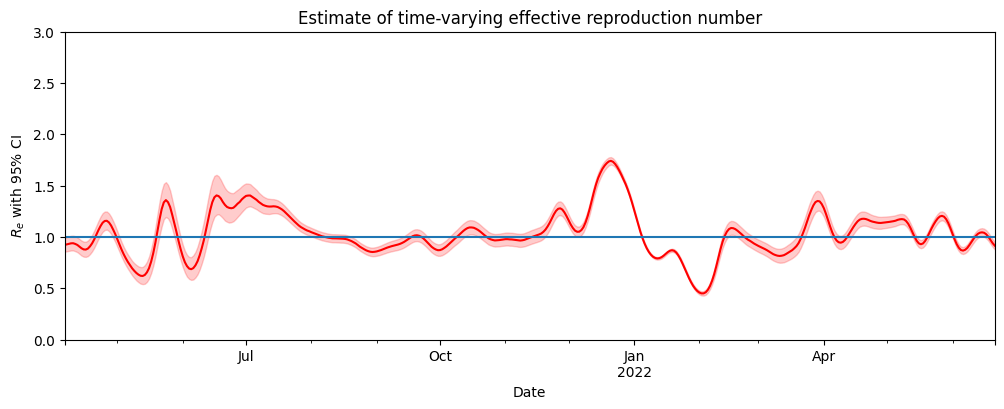

,cases,R_mean,R_var,Q0.025,Q0.5,Q0.975
2022-06-17,892.0,1.025260,0.000404,0.986073,1.025130,1.064787
2022-06-18,1024.0,1.001147,0.000390,0.962549,1.001015,1.040438
2022-06-19,1007.0,0.970591,0.000377,0.933253,0.970464,1.008928
2022-06-20,990.0,0.939958,0.000364,0.902915,0.939828,0.977821
2022-06-21,973.0,0.915470,0.000357,0.878795,0.915339,0.952975


In [29]:
# TEST ON CLINICAL DATA
reported_cases = pd.Series(cases['cases'].values, index=cases.index).round().astype(int)

ch_time_varying_r = covid19.r_covid(reported_cases)

fig, ax = plt.subplots(1,1, figsize=(12, 4))

ch_time_varying_r.loc[:,'Q0.5'].plot(ax=ax, color='red')
ax.fill_between(ch_time_varying_r.index, 
                    ch_time_varying_r['Q0.025'], 
                    ch_time_varying_r['Q0.975'], 
                    color='red', alpha=0.2)
ax.set_xlabel('Date')
ax.set_ylabel('$R_e$ with 95% CI')
ax.set_ylim([0,3])
ax.axhline(y=1)
ax.set_title('Estimate of time-varying effective reproduction number')
plt.show()

ch_time_varying_r.tail()

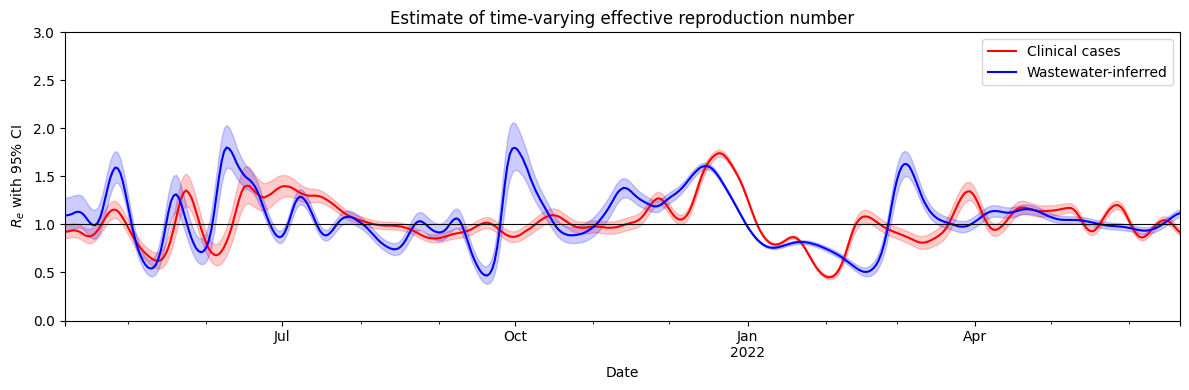

             cases    R_mean     R_var    Q0.025      Q0.5    Q0.975
2022-06-17   892.0  1.024215  0.000405  0.985231  1.024086  1.063921
2022-06-18  1024.0  1.001230  0.000392  0.963202  1.001102  1.040211
2022-06-19  1007.0  0.973077  0.000378  0.935403  0.972947  1.011526
2022-06-20   990.0  0.943075  0.000366  0.905826  0.942943  0.980971
2022-06-21   973.0  0.917839  0.000358  0.881263  0.917710  0.955182
            cases    R_mean     R_var    Q0.025      Q0.5    Q0.975
2022-06-17  852.0  1.057121  0.000411  1.017766  1.056992  1.097257
2022-06-18  887.0  1.077084  0.000415  1.037547  1.076955  1.117357
2022-06-19  888.0  1.094134  0.000416  1.054376  1.094007  1.134413
2022-06-20  891.0  1.108730  0.000415  1.069234  1.108605  1.148924
2022-06-21  900.0  1.118209  0.000409  1.078761  1.118086  1.158355


In [30]:
reported_cases = cases['cases'].round().astype(int)

clinical_r = covid19.r_covid(reported_cases)
wastewater_r = covid19.r_covid(infects)


fig, ax = plt.subplots(1, 1, figsize=(12, 4))

clinical_r['Q0.5'].plot(ax=ax, color='red', label='Clinical cases')
ax.fill_between(clinical_r.index, clinical_r['Q0.025'], clinical_r['Q0.975'],
                color='red', alpha=0.2)

wastewater_r['Q0.5'].plot(ax=ax, color='blue', label='Wastewater-inferred')
ax.fill_between(wastewater_r.index, wastewater_r['Q0.025'], wastewater_r['Q0.975'],
                color='blue', alpha=0.2)

ax.set_xlabel('Date')
ax.set_ylabel('$R_e$ with 95% CI')
ax.set_ylim([0, 3])
ax.axhline(y=1, color='k', lw=0.8)
ax.set_title('Estimate of time-varying effective reproduction number')
ax.legend()
plt.tight_layout()
plt.show()

print(clinical_r.tail())
print(wastewater_r.tail())